In [19]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [20]:
from utils import *

In [21]:
import warnings

def fxn():
    warnings.warn("deprecated", RuntimeWarning)
with warnings.catch_warnings(action="ignore"):
    fxn()

In [22]:
d, n , q = 50 , 10000 , 2
X = np.random.randn( d , n )
y = ( np.sum( X , axis = 0 ) <= 0.5 ).astype(np.int64)

In [23]:
classifier = Classifier(0.01 , 100 , q , lam = 0.0 ,  batch_size = 256)
classifier.fit(X,y)

Epochs 1 | Loss 0.5857 | Accuracy 97.38 %


In [24]:
q = 2
# Download MNIST dataset
train = MNIST(root="./data", train=True, download=True)
test = MNIST(root="./data", train=False, download=True)

# Convert to ndarray and normalize
X_train = train.data.numpy().astype(np.float32) / 255.0
X_test = test.data.numpy().astype(np.float32) / 255.0

# labeling: 0: digit <= 5 | 1: digit > 5 
y_train = (train.targets.numpy() > 5).astype(np.int64)
y_test = (test.targets.numpy() > 5).astype(np.int64)

# Flatten
X_train = X_train.reshape(-1 , 784).T
X_test = X_test.reshape(-1 , 784).T

In [28]:
classifier = Classifier( 0.1 , 100 , q , lam = 0.0, batch_size = 128 )
idx = np.random.choice( np.arange(X_train.shape[-1]) , size = X_train.shape[-1] , replace=False )
classifier.fit( X_train[:,idx] , y_train[idx] )

Epochs 1 | Loss 0.3396 | Accuracy 86.38 %


In [29]:
y_test_pred = classifier.classify(X_test)
test_accuracy = 100 * classifier.accuracy(y_test,y_test_pred)
print(f'Test accuracy: {test_accuracy:.2f} %')

Test accuracy: 88.44 %


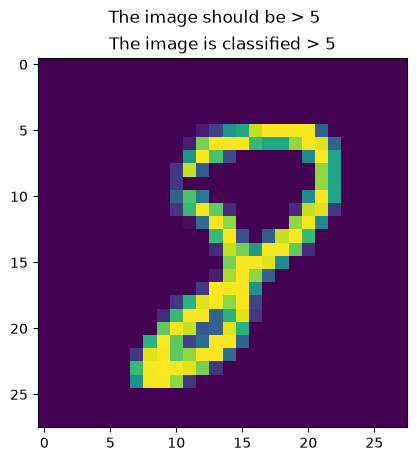

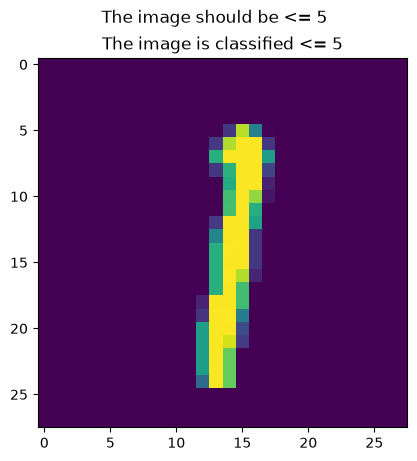

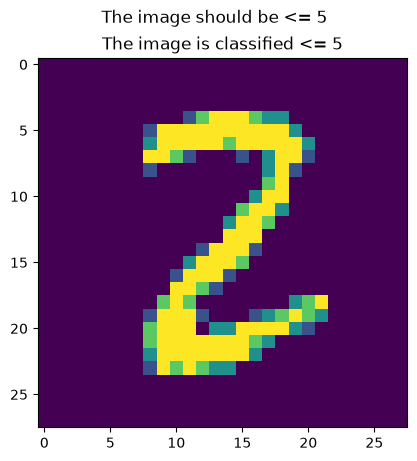

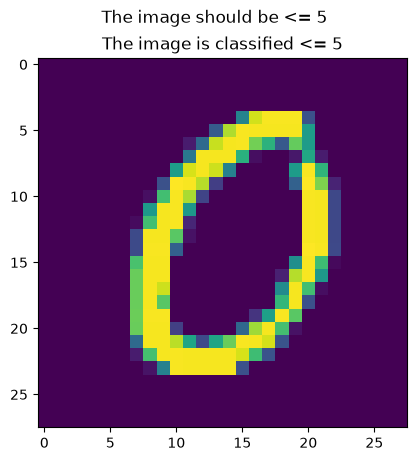

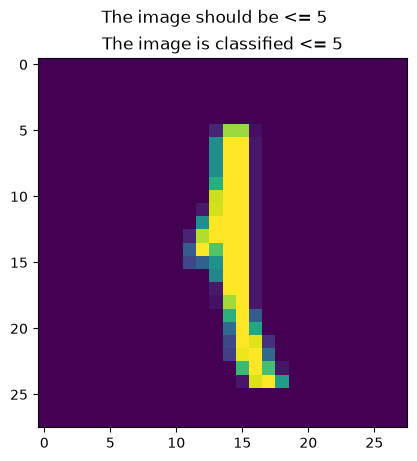

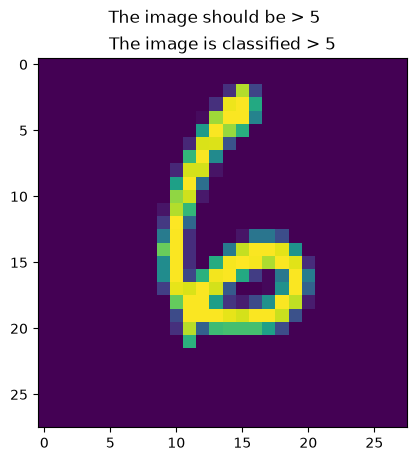

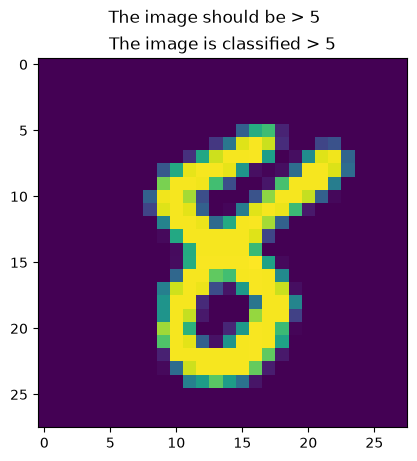

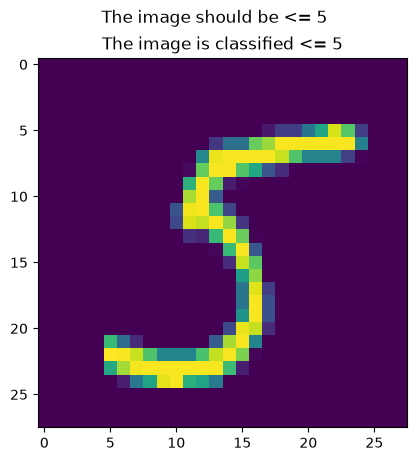

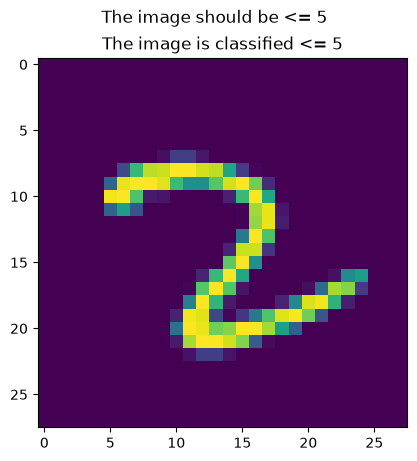

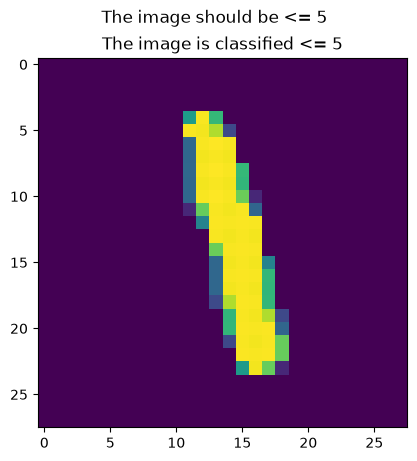

In [30]:
classif = { 0.: '<= 5', 1.:'> 5' }
for k in np.random.choice( np.arange(5000) , size = 10 , replace=False):
    x_plot = X_test[:,k].reshape(28,-1)
    plt.imshow(x_plot)
    plt.suptitle(f'The image should be {classif[ y_test[k] ]}')
    plt.title(f'The image is classified {classif[ y_test_pred[k] ]}')
    plt.show()